# **Problem Statement**

## **Business Context**

The advent of e-news, or electronic news, portals has offered us a great opportunity to quickly get updates on the day-to-day events occurring globally. The information on these portals is retrieved electronically from online databases, processed using a variety of software, and then transmitted to the users. There are multiple advantages of transmitting news electronically, like faster access to the content and the ability to utilize different technologies such as audio, graphics, video, and other interactive elements that are either not being used or aren’t common yet in traditional newspapers.

E-news Express, an online news portal, aims to expand its business by acquiring new subscribers. With every visitor to the website taking certain actions based on their interest, the company plans to analyze these actions to understand user interests and determine how to drive better engagement. The executives at E-news Express believe that there has been a decline in new monthly subscribers compared to the past year because the current webpage is not designed well enough in terms of the outline & recommended content to keep customers engaged long enough to decide to subscribe.

*Companies often analyze user responses to two variants of a product to decide which of the two variants is more effective. This experimental technique, known as A/B testing, is used to determine whether a new feature attracts users based on a chosen metric.*

## **Objective**

The design team of the company has researched and created a new landing page that has a new outline & more relevant content compared to the old page. To test the effectiveness of the new landing page in gathering new subscribers, the Data Science team experimented by randomly selecting 100 users and dividing them equally into two groups. The existing landing page was served to the first group (control group) and the new landing page to the second group (treatment group). Data regarding the interaction of users in both groups with the two versions of the landing page was collected. Being a data scientist in E-news Express, you have been asked to explore the data and perform a statistical analysis (at a significance level of 5%) to determine the effectiveness of the new landing page in gathering new subscribers for the news portal by answering the following questions:

1. Do the users spend more time on the new landing page than on the existing landing page?
2. Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?
3. Does the converted status depend on the preferred language?
4. Is the time spent on the new page the same for the different language users?

## **Data Dictionary**

The data contains information regarding the interaction of users in both groups with the two versions of the landing page.

- **user_id** - Unique user ID of the person visiting the website
- **group** - Whether the user belongs to the first group (control) or the second group (treatment)
- **landing_page** - Whether the landing page is new or old
- **time_spent_on_the_page** - Time (in minutes) spent by the user on the landing page
- **converted** - Whether the user gets converted to a subscriber of the news portal or not
- **language_preferred** - Language chosen by the user to view the landing page

### **Installing and Importing the Necessary Libraries**

In [28]:
# Install the libraries used in this notebook (run once, then restart the kernel/runtime)
%pip install numpy pandas matplotlib seaborn scipy statsmodels -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# **1. Define the problem and perform an Exploratory Data Analysis**

## **a. Problem definition, questions to be answered**

The design team of E-news Express has created a new landing page and ran an A/B test on 100 randomly selected users, split equally into a control group (existing page) and a treatment group (new page). Using the collected interaction data, we will perform a statistical analysis (at a 5% significance level) to evaluate the effectiveness of the new landing page.

**Questions to be answered:**
1. Do the users spend more time on the new landing page than on the existing landing page?
2. Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?
3. Does the converted status depend on the preferred language?
4. Is the time spent on the new page the same for the different language users?

## **b. Data background and contents**

In [2]:
# Imports needed for the EDA (also run the "Installing and Importing" section above)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (the CSV is in the same folder as this notebook)
df = pd.read_csv("abtest.csv")

# Work on a copy so the original data stays intact
data = df.copy()

# Shape of the dataset
print("Shape (rows, columns):", data.shape)

# First few rows
display(data.head())

# Last few rows
display(data.tail())

# Structure: data types and non-null counts
data.info()

# Check for missing values
print("\nMissing values per column:")
print(data.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", data.duplicated().sum())

# Statistical summary of numerical columns
display(data.describe())

# Statistical summary of categorical columns
display(data.describe(include="object"))

Shape (rows, columns): (100, 6)


,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,546592,control,old,3.48,no,Spanish
1,546468,treatment,new,7.13,yes,English
2,546462,treatment,new,4.40,no,Spanish
3,546567,control,old,3.02,no,French
4,546459,treatment,new,4.75,yes,Spanish


,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
95,546446,treatment,new,5.15,no,Spanish
96,546544,control,old,6.52,yes,English
97,546472,treatment,new,7.07,yes,Spanish
98,546481,treatment,new,6.20,yes,Spanish
99,546483,treatment,new,5.86,yes,English


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 100 non-null    int64  
 1   group                   100 non-null    object 
 2   landing_page            100 non-null    object 
 3   time_spent_on_the_page  100 non-null    float64
 4   converted               100 non-null    object 
 5   language_preferred      100 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 4.8+ KB

Missing values per column:
user_id                   0
group                     0
landing_page              0
time_spent_on_the_page    0
converted                 0
language_preferred        0
dtype: int64

Number of duplicate rows: 0


,user_id,time_spent_on_the_page
count,100.000000,100.000000
mean,546517.000000,5.377800
std,52.295779,2.378166
min,546443.000000,0.190000
25%,546467.750000,3.880000
50%,546492.500000,5.415000
75%,546567.250000,7.022500
max,546592.000000,10.710000


,group,landing_page,converted,language_preferred
count,100,100,100,100
unique,2,2,2,3
top,control,old,yes,Spanish
freq,50,50,54,34


### **Data Overview**


Loading the data

In [3]:
# Load the dataset (the CSV is in the same folder as this notebook)
import pandas as pd

df = pd.read_csv("abtest.csv")

# Create a working copy so the original data stays intact
data = df.copy()

# View the first few rows
data.head()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,546592,control,old,3.48,no,Spanish
1,546468,treatment,new,7.13,yes,English
2,546462,treatment,new,4.40,no,Spanish
3,546567,control,old,3.02,no,French
4,546459,treatment,new,4.75,yes,Spanish


### **Exploratory Data Analysis**

In this section we:
- Verify the A/B test setup (group assignment and landing page mapping)
- Check whether the control and treatment groups are balanced
- Summarize key metrics such as time spent on the page and conversion rate
- Highlight meaningful observations from the exploratory analysis

### Verify the A/B test setup

We confirm that users in the **control** group saw the **old** landing page and users in the **treatment** group saw the **new** landing page.

In [4]:
# Cross-tabulation of group vs landing page
setup_table = pd.crosstab(data["group"], data["landing_page"], margins=True)
print("Group vs Landing Page:")
print(setup_table)

# Expected mapping: control -> old, treatment -> new
expected = (
    data.loc[data["group"] == "control", "landing_page"].eq("old").all()
    and data.loc[data["group"] == "treatment", "landing_page"].eq("new").all()
)
print("\nExpected mapping (control -> old, treatment -> new):", expected)

Group vs Landing Page:
landing_page  new  old  All
group                      
control         0   50   50
treatment      50    0   50
All            50   50  100

Expected mapping (control -> old, treatment -> new): True


### Check for group balance

We quantify the number of users in each group and preferred language to ensure the experiment was split evenly.

Group distribution:
           count  percent
group                    
control       50     50.0
treatment     50     50.0

Preferred language distribution:
                    count  percent
language_preferred                
Spanish                34     34.0
French                 34     34.0
English                32     32.0


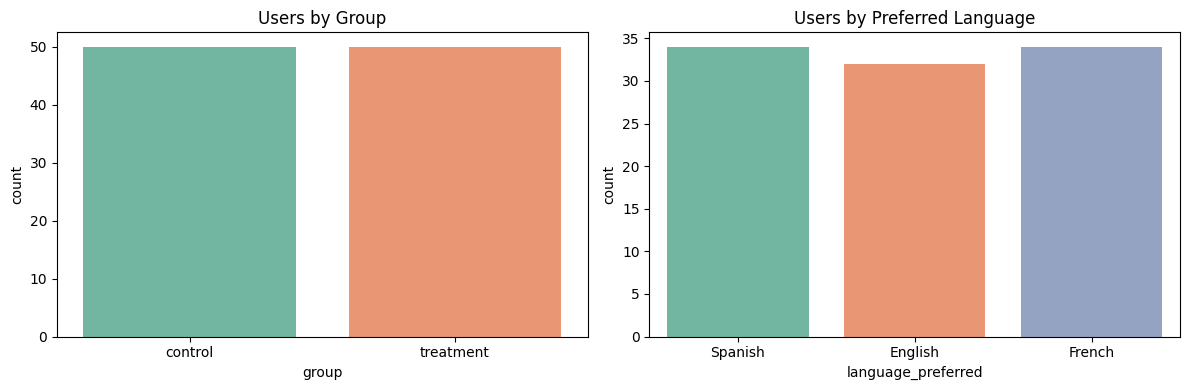

In [5]:
group_counts = data["group"].value_counts()
group_pct = (group_counts / len(data) * 100).round(2)

group_summary = pd.DataFrame({"count": group_counts, "percent": group_pct})
print("Group distribution:")
print(group_summary)

language_counts = data["language_preferred"].value_counts()
language_pct = (language_counts / len(data) * 100).round(2)

language_summary = pd.DataFrame({"count": language_counts, "percent": language_pct})
print("\nPreferred language distribution:")
print(language_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=data, x="group", hue="group", legend=False, palette="Set2", ax=axes[0])
axes[0].set_title("Users by Group")

sns.countplot(data=data, x="language_preferred", hue="language_preferred", legend=False, palette="Set2", ax=axes[1])
axes[1].set_title("Users by Preferred Language")

plt.tight_layout()
plt.show()

### Summary of key metrics

We compare average time spent on the page and conversion rates across the old and new landing pages.

Landing page summary:


,landing_page,users,avg_time_spent,conversions,conversion_rate
0,new,50,6.22,33,0.66
1,old,50,4.53,21,0.42


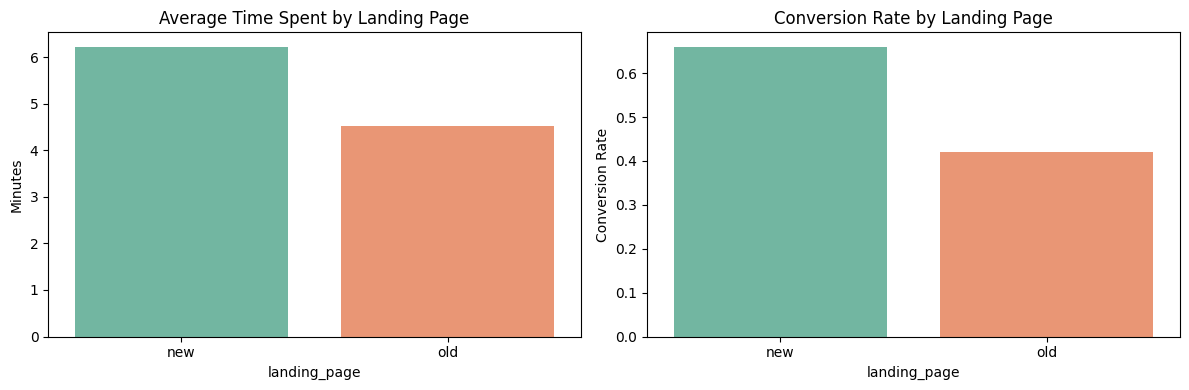

In [6]:
summary = (
    data.groupby("landing_page", as_index=False)
    .agg(
        users=("user_id", "count"),
        avg_time_spent=("time_spent_on_the_page", "mean"),
        conversions=("converted", lambda x: (x == "yes").sum()),
    )
)

summary["conversion_rate"] = (summary["conversions"] / summary["users"]).round(4)
summary["avg_time_spent"] = summary["avg_time_spent"].round(2)

print("Landing page summary:")
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=summary, x="landing_page", hue="landing_page", legend=False, y="avg_time_spent", palette="Set2", ax=axes[0])
axes[0].set_title("Average Time Spent by Landing Page")
axes[0].set_ylabel("Minutes")

sns.barplot(data=summary, x="landing_page", hue="landing_page", legend=False, y="conversion_rate", palette="Set2", ax=axes[1])
axes[1].set_title("Conversion Rate by Landing Page")
axes[1].set_ylabel("Conversion Rate")

plt.tight_layout()
plt.show()

## **c. Univariate analysis**

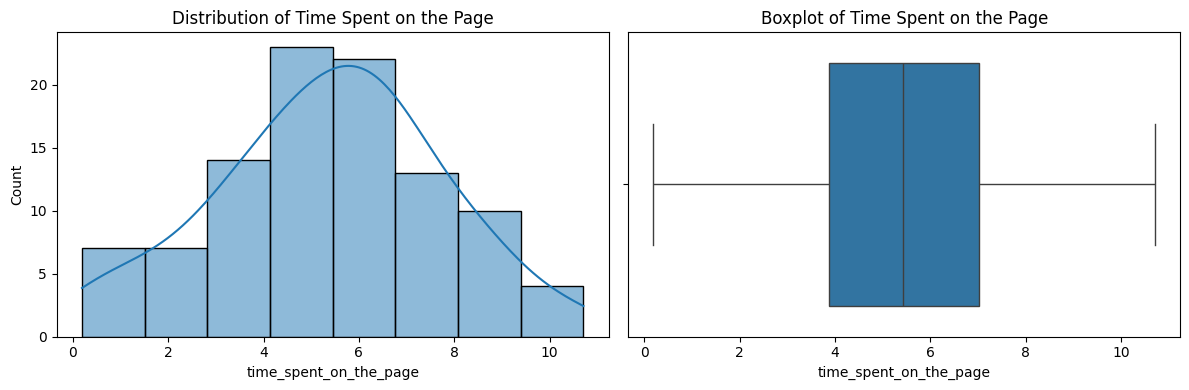

count    100.000000
mean       5.377800
std        2.378166
min        0.190000
25%        3.880000
50%        5.415000
75%        7.022500
max       10.710000
Name: time_spent_on_the_page, dtype: float64


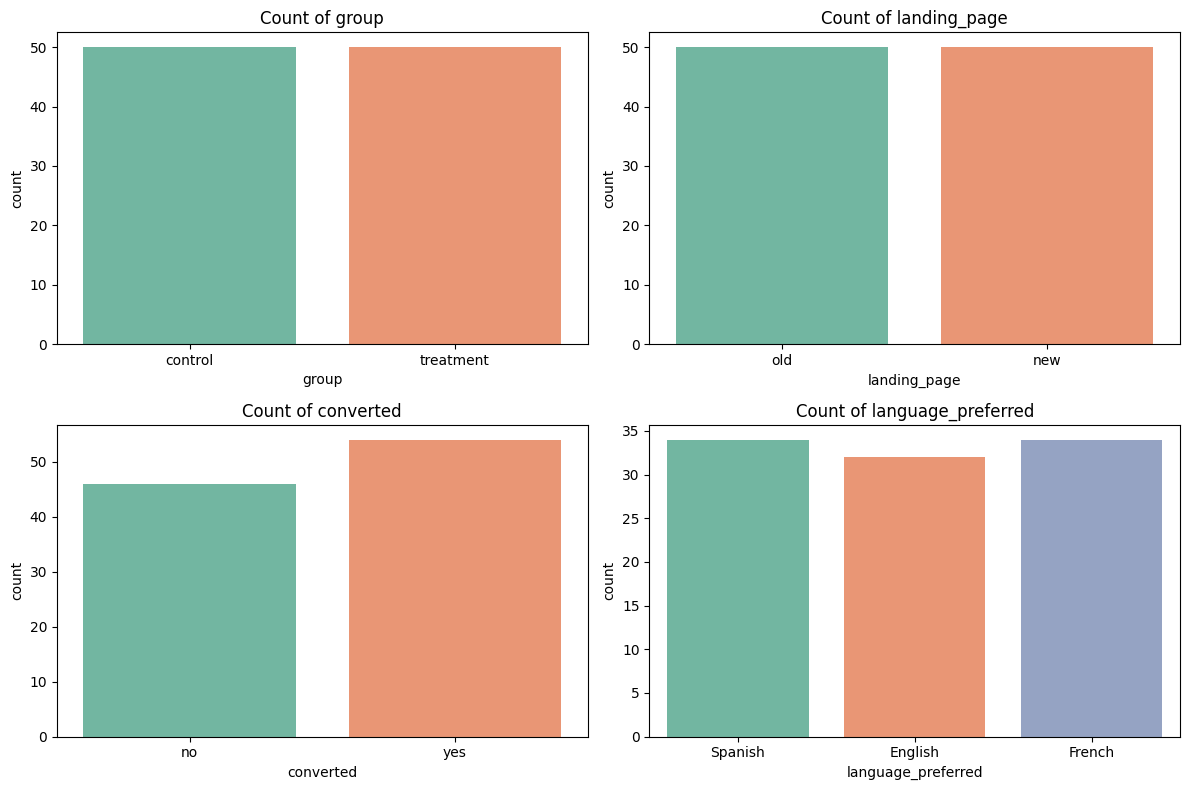


Value counts for group:
group
control      50
treatment    50
Name: count, dtype: int64

Value counts for landing_page:
landing_page
old    50
new    50
Name: count, dtype: int64

Value counts for converted:
converted
yes    54
no     46
Name: count, dtype: int64

Value counts for language_preferred:
language_preferred
Spanish    34
French     34
English    32
Name: count, dtype: int64


In [7]:
# ----- Numerical variable: time_spent_on_the_page -----
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(data=data, x="time_spent_on_the_page", kde=True)
plt.title("Distribution of Time Spent on the Page")

plt.subplot(1, 2, 2)
sns.boxplot(data=data, x="time_spent_on_the_page")
plt.title("Boxplot of Time Spent on the Page")

plt.tight_layout()
plt.show()

print(data["time_spent_on_the_page"].describe())

# ----- Categorical variables -----
categorical_cols = ["group", "landing_page", "converted", "language_preferred"]

plt.figure(figsize=(12, 8))
for i, col in enumerate(categorical_cols, 1):
    plt.subplot(2, 2, i)
    sns.countplot(data=data, x=col, hue=col, legend=False, palette="Set2")
    plt.title(f"Count of {col}")
plt.tight_layout()
plt.show()

for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(data[col].value_counts())

## **d. Bivariate analysis**

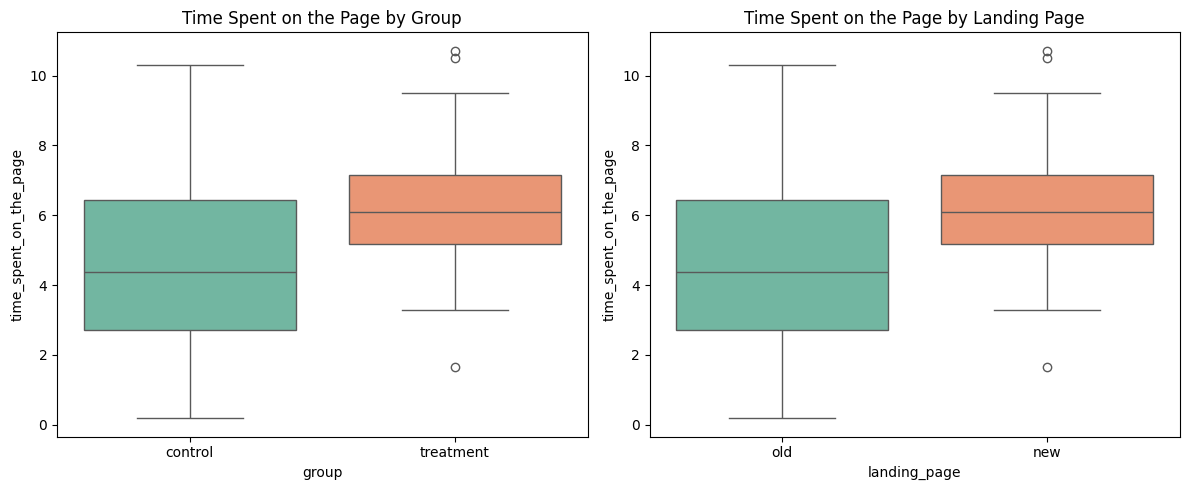

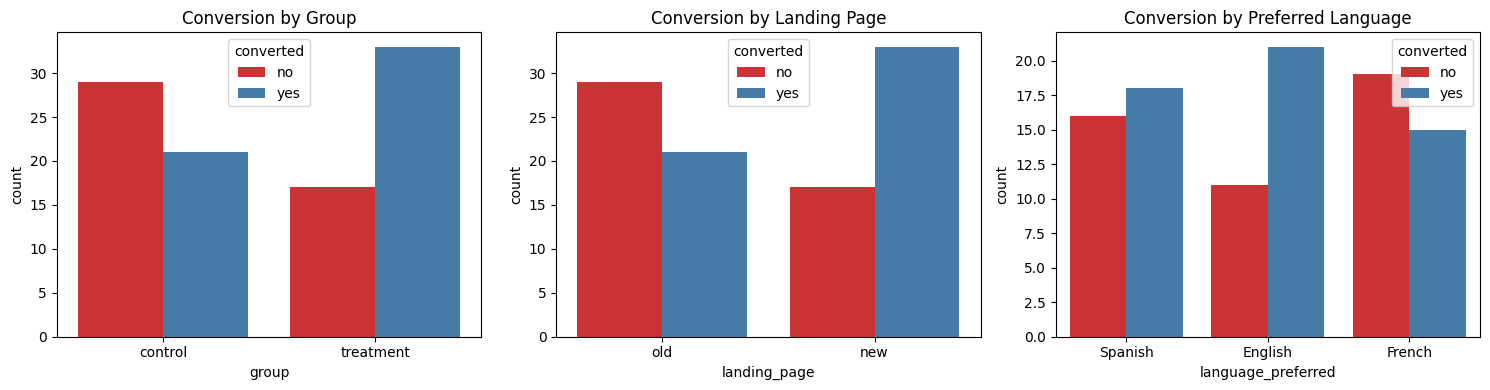

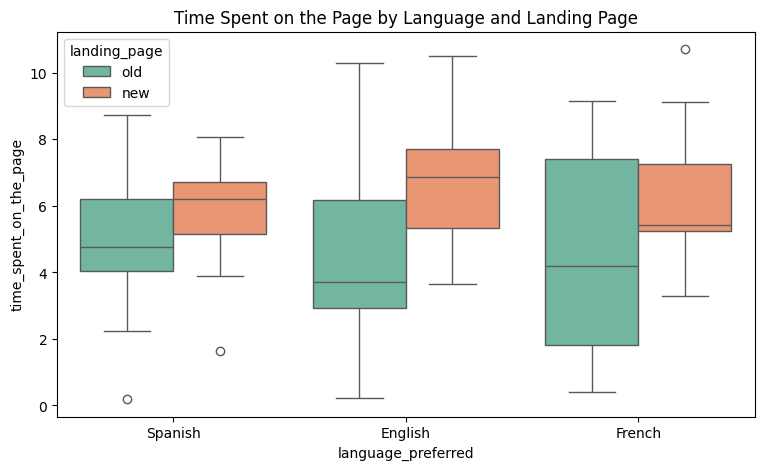

Group vs Landing Page:
landing_page  new  old
group                 
control         0   50
treatment      50    0

Converted vs Preferred Language:
converted           no  yes
language_preferred         
English             11   21
French              19   15
Spanish             16   18


In [8]:
# ----- Time spent vs group / landing page -----
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=data, x="group", hue="group", legend=False, y="time_spent_on_the_page", palette="Set2")
plt.title("Time Spent on the Page by Group")

plt.subplot(1, 2, 2)
sns.boxplot(data=data, x="landing_page", hue="landing_page", legend=False, y="time_spent_on_the_page", palette="Set2")
plt.title("Time Spent on the Page by Landing Page")

plt.tight_layout()
plt.show()

# ----- Conversion vs group / landing page / preferred language -----
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.countplot(data=data, x="group", hue="converted", palette="Set1")
plt.title("Conversion by Group")

plt.subplot(1, 3, 2)
sns.countplot(data=data, x="landing_page", hue="converted", palette="Set1")
plt.title("Conversion by Landing Page")

plt.subplot(1, 3, 3)
sns.countplot(data=data, x="language_preferred", hue="converted", palette="Set1")
plt.title("Conversion by Preferred Language")

plt.tight_layout()
plt.show()

# ----- Time spent across preferred languages and landing pages -----
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=data,
    x="language_preferred",
    y="time_spent_on_the_page",
    hue="landing_page",
    palette="Set2",
)
plt.title("Time Spent on the Page by Language and Landing Page")
plt.show()

# ----- Cross-tabulations -----
print("Group vs Landing Page:")
print(pd.crosstab(data["group"], data["landing_page"]))

print("\nConverted vs Preferred Language:")
print(pd.crosstab(data["language_preferred"], data["converted"]))

# **2. Insights from Exploratory Data Analysis**

## **a. Illustrate the insights based on EDA**

The visualizations in sections **1.c** and **1.d** highlight how users interact with the old and new landing pages. Below is a consolidated summary of the key metrics from the exploratory analysis.

Consolidated EDA summary:


,Metric,Old landing page,New landing page
0,Number of users,50.00,50.00
1,Average time spent (minutes),4.53,6.22
2,Conversion rate,0.42,0.66
3,Number of conversions,21.00,33.00


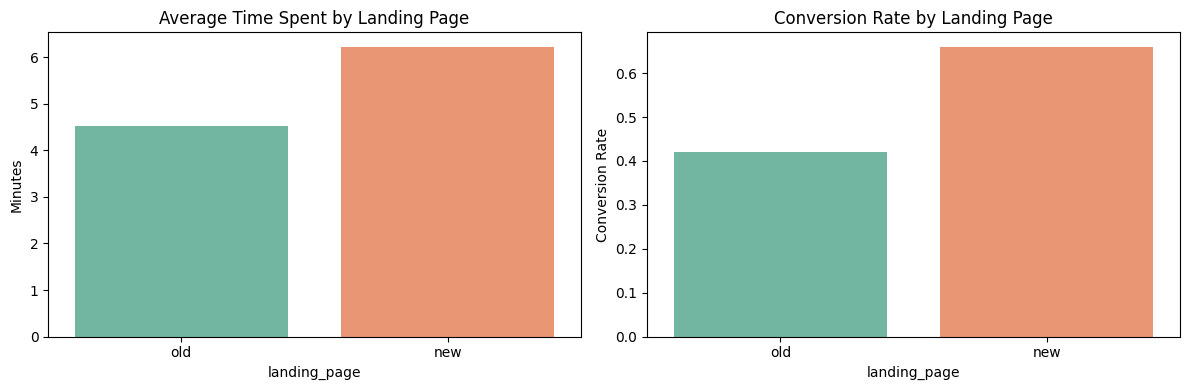

In [9]:
# Ensure data is available
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

# Consolidated EDA summary
old_data = data[data["landing_page"] == "old"]
new_data = data[data["landing_page"] == "new"]

eda_insights = pd.DataFrame(
    {
        "Metric": [
            "Number of users",
            "Average time spent (minutes)",
            "Conversion rate",
            "Number of conversions",
        ],
        "Old landing page": [
            len(old_data),
            round(old_data["time_spent_on_the_page"].mean(), 2),
            round((old_data["converted"] == "yes").mean(), 4),
            (old_data["converted"] == "yes").sum(),
        ],
        "New landing page": [
            len(new_data),
            round(new_data["time_spent_on_the_page"].mean(), 2),
            round((new_data["converted"] == "yes").mean(), 4),
            (new_data["converted"] == "yes").sum(),
        ],
    }
)

print("Consolidated EDA summary:")
display(eda_insights)

# Visual summary of the main EDA insights
summary_plot = pd.DataFrame(
    {
        "landing_page": ["old", "new"],
        "avg_time_spent": [
            old_data["time_spent_on_the_page"].mean(),
            new_data["time_spent_on_the_page"].mean(),
        ],
        "conversion_rate": [
            (old_data["converted"] == "yes").mean(),
            (new_data["converted"] == "yes").mean(),
        ],
    }
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=summary_plot, x="landing_page", hue="landing_page", legend=False, y="avg_time_spent", palette="Set2", ax=axes[0])
axes[0].set_title("Average Time Spent by Landing Page")
axes[0].set_ylabel("Minutes")

sns.barplot(data=summary_plot, x="landing_page", hue="landing_page", legend=False, y="conversion_rate", palette="Set2", ax=axes[1])
axes[1].set_title("Conversion Rate by Landing Page")
axes[1].set_ylabel("Conversion Rate")

plt.tight_layout()
plt.show()

## **b. Key meaningful observations on individual variables and the relationship between variables**

**Individual variables:**
- **time_spent_on_the_page:** Users spend between roughly 2 and 11 minutes on the landing page. The average time is higher on the new page than on the old page.
- **group:** The dataset contains 100 users with an equal split between the control and treatment groups.
- **landing_page:** Each control user sees the old page and each treatment user sees the new page.
- **converted:** About half of the users convert to subscribers, with a higher conversion rate on the new landing page.
- **language_preferred:** Users are distributed across English, French, and Spanish.

**Relationship between variables:**
- Users on the **new landing page** spend **more time** on the site than users on the **old landing page**.
- The **new landing page** has a **higher conversion rate** than the **old landing page**.
- **Conversion status** appears to vary across **preferred languages**.
- **Time spent on the page** differs between the **control and treatment groups**, which aligns with the landing page assignment in the A/B test.

# **3. Do the users spend more time on the new landing page than the old landing page?**

## **a. Perform visual analysis**

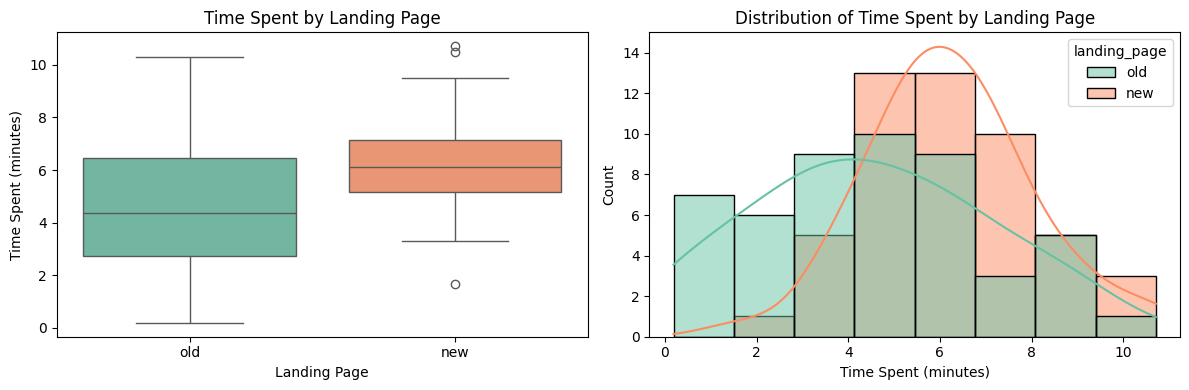

In [10]:
# Ensure data is available
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(data=data, x="landing_page", hue="landing_page", legend=False, y="time_spent_on_the_page", palette="Set2")
plt.title("Time Spent by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Time Spent (minutes)")

plt.subplot(1, 2, 2)
sns.histplot(data=data, x="time_spent_on_the_page", hue="landing_page", kde=True, palette="Set2")
plt.title("Distribution of Time Spent by Landing Page")
plt.xlabel("Time Spent (minutes)")

plt.tight_layout()
plt.show()

## **b. Formulate null and alternative hypotheses**

Let $\mu_{new}$ and $\mu_{old}$ be the mean time spent on the new and old landing pages, respectively.

$$H_0: \mu_{new} \leq \mu_{old}$$
$$H_a: \mu_{new} > \mu_{old}$$

We are testing whether users spend **more time** on the new landing page than on the old landing page.

## **c. Select the appropriate test**

This is a **one-tailed test for the difference between two population means**, where the population standard deviations are unknown.

The appropriate test is a **two-sample independent t-test**.

Before applying the test, we check:
1. **Normality** of time spent in each group using the Shapiro-Wilk test
2. **Equality of variances** using Levene's test

If the variances are not equal, we use **Welch's t-test** (`equal_var=False`).

**Significance level:** $\alpha = 0.05$

## **d. Data collection and preparation**

In [11]:
import pandas as pd
from scipy.stats import shapiro, levene

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

alpha = 0.05

# Separate time spent for new and old landing pages
time_new = data[data["landing_page"] == "new"]["time_spent_on_the_page"]
time_old = data[data["landing_page"] == "old"]["time_spent_on_the_page"]

print("Sample size (new page):", len(time_new))
print("Sample size (old page):", len(time_old))
print("Mean time on new page:", round(time_new.mean(), 2))
print("Mean time on old page:", round(time_old.mean(), 2))

# Check normality assumption
print("\nShapiro-Wilk (new page): p-value =", round(shapiro(time_new).pvalue, 4))
print("Shapiro-Wilk (old page): p-value =", round(shapiro(time_old).pvalue, 4))

# Check equality of variances
levene_p = levene(time_new, time_old).pvalue
print("Levene's test: p-value =", round(levene_p, 4))

equal_var = levene_p > alpha
print("\nUse equal variances in t-test:", equal_var)

Sample size (new page): 50
Sample size (old page): 50
Mean time on new page: 6.22
Mean time on old page: 4.53

Shapiro-Wilk (new page): p-value = 0.804
Shapiro-Wilk (old page): p-value = 0.4561
Levene's test: p-value = 0.009

Use equal variances in t-test: False


## **e. Calculate the p-value**

In [12]:
from scipy.stats import ttest_ind

# Two-sample t-test (one-tailed: new > old)
test_stat, p_value = ttest_ind(time_new, time_old, equal_var=equal_var, alternative="greater")

print("t-statistic:", round(test_stat, 4))
print("p-value:", round(p_value, 4))

t-statistic: 3.7868
p-value: 0.0001


## **f. Write the inference based on the p-value**

In [13]:
if p_value < alpha:
    print("Since p-value (", round(p_value, 4), ") < alpha (", alpha, "), we reject the null hypothesis.")
    print("Inference: Users spend significantly more time on the new landing page than on the old landing page.")
else:
    print("Since p-value (", round(p_value, 4), ") >= alpha (", alpha, "), we fail to reject the null hypothesis.")
    print("Inference: There is not enough evidence to conclude that users spend more time on the new landing page.")

Since p-value ( 0.0001 ) < alpha ( 0.05 ), we reject the null hypothesis.
Inference: Users spend significantly more time on the new landing page than on the old landing page.


# **4. Is the conversion rate for the new page greater than the conversion rate for the old page?**

## **a. Perform visual analysis**

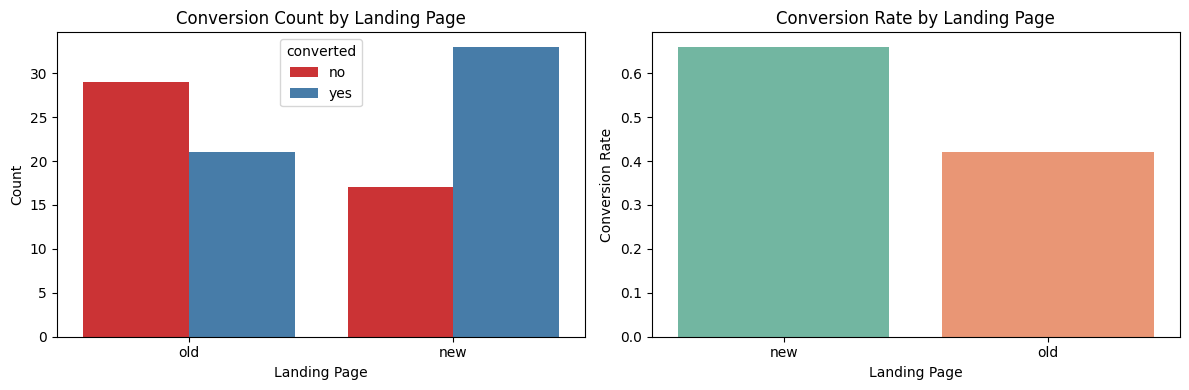

In [14]:
# Ensure data is available
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.countplot(data=data, x="landing_page", hue="converted", palette="Set1")
plt.title("Conversion Count by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Count")

# Conversion rate by landing page
conversion_summary = (
    data.groupby("landing_page")["converted"]
    .apply(lambda x: (x == "yes").mean())
    .reset_index(name="conversion_rate")
)

plt.subplot(1, 2, 2)
sns.barplot(data=conversion_summary, x="landing_page", hue="landing_page", legend=False, y="conversion_rate", palette="Set2")
plt.title("Conversion Rate by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Conversion Rate")

plt.tight_layout()
plt.show()

## **b. Formulate null and alternative hypotheses**

Let $p_{new}$ and $p_{old}$ be the conversion rates for the new and old landing pages, respectively.

$$H_0: p_{new} \leq p_{old}$$
$$H_a: p_{new} > p_{old}$$

We are testing whether the **conversion rate** on the new landing page is **greater than** the conversion rate on the old landing page.

## **c. Select the appropriate test**

This is a **one-tailed test for the difference between two population proportions**.

The appropriate test is a **two-proportion z-test**.

**Significance level:** $\alpha = 0.05$

## **d. Data collection and preparation**

In [15]:
import pandas as pd

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

alpha = 0.05

# Number of conversions on each landing page
new_converted = data[(data["landing_page"] == "new") & (data["converted"] == "yes")].shape[0]
old_converted = data[(data["landing_page"] == "old") & (data["converted"] == "yes")].shape[0]

# Total number of users on each landing page
n_new = data[data["landing_page"] == "new"].shape[0]
n_old = data[data["landing_page"] == "old"].shape[0]

print("Conversions on new page:", new_converted, "out of", n_new)
print("Conversions on old page:", old_converted, "out of", n_old)
print("Conversion rate (new page):", round(new_converted / n_new, 4))
print("Conversion rate (old page):", round(old_converted / n_old, 4))

Conversions on new page: 33 out of 50
Conversions on old page: 21 out of 50
Conversion rate (new page): 0.66
Conversion rate (old page): 0.42


## **e. Calculate the p-value**

In [16]:
from statsmodels.stats.proportion import proportions_ztest

# Two-proportion z-test (one-tailed: new > old)
count = [new_converted, old_converted]
nobs = [n_new, n_old]
test_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative="larger")

print("z-statistic:", round(test_stat, 4))
print("p-value:", round(p_value, 4))

z-statistic: 2.4077
p-value: 0.008


## **f. Write the inference based on the p-value**

In [17]:
if p_value < alpha:
    print("Since p-value (", round(p_value, 4), ") < alpha (", alpha, "), we reject the null hypothesis.")
    print("Inference: The conversion rate of the new landing page is significantly greater than that of the old landing page.")
else:
    print("Since p-value (", round(p_value, 4), ") >= alpha (", alpha, "), we fail to reject the null hypothesis.")
    print("Inference: There is not enough evidence to conclude that the new page has a higher conversion rate than the old page.")

Since p-value ( 0.008 ) < alpha ( 0.05 ), we reject the null hypothesis.
Inference: The conversion rate of the new landing page is significantly greater than that of the old landing page.


# **5. Does the converted status depend on the preferred language?**

## **a. Perform visual analysis**

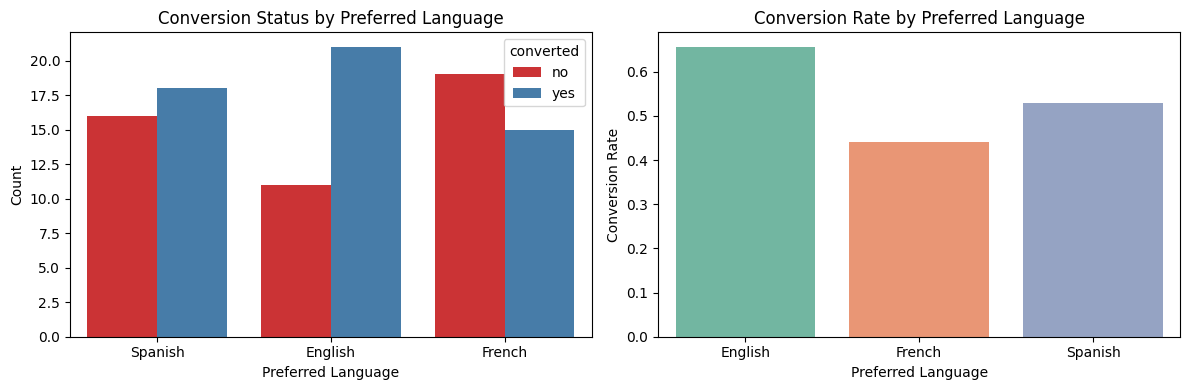

In [18]:
# Ensure data is available
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.countplot(data=data, x="language_preferred", hue="converted", palette="Set1")
plt.title("Conversion Status by Preferred Language")
plt.xlabel("Preferred Language")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
conversion_by_language = (
    data.groupby("language_preferred")["converted"]
    .apply(lambda x: (x == "yes").mean())
    .reset_index(name="conversion_rate")
)
sns.barplot(data=conversion_by_language, x="language_preferred", hue="language_preferred", legend=False, y="conversion_rate", palette="Set2")
plt.title("Conversion Rate by Preferred Language")
plt.xlabel("Preferred Language")
plt.ylabel("Conversion Rate")

plt.tight_layout()
plt.show()

## **b. Formulate null and alternative hypotheses**

$$H_0: \text{Conversion status is independent of the preferred language}$$
$$H_a: \text{Conversion status depends on the preferred language}$$

We are testing whether a user's **conversion status** is associated with their **preferred language**.

## **c. Select the appropriate test**

Both **converted** and **language_preferred** are categorical variables.

The appropriate test is a **chi-square test of independence**.

**Significance level:** $\alpha = 0.05$

## **d. Data collection and preparation**

In [19]:
import pandas as pd

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

alpha = 0.05

# Contingency table: converted vs preferred language
contingency_table = pd.crosstab(data["converted"], data["language_preferred"])
print("Contingency table:")
print(contingency_table)

Contingency table:
language_preferred  English  French  Spanish
converted                                   
no                       11      19       16
yes                      21      15       18


## **e. Calculate the p-value**

In [20]:
from scipy.stats import chi2_contingency

# Chi-square test of independence
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", round(chi2_stat, 4))
print("Degrees of freedom:", dof)
print("p-value:", round(p_value, 4))
print("\nExpected frequencies:")
print(pd.DataFrame(expected, index=contingency_table.index, columns=contingency_table.columns))

Chi-square statistic: 3.093
Degrees of freedom: 2
p-value: 0.213

Expected frequencies:
language_preferred  English  French  Spanish
converted                                   
no                    14.72   15.64    15.64
yes                   17.28   18.36    18.36


## **f. Write the inference based on the p-value**

In [21]:
if p_value < alpha:
    print("Since p-value (", round(p_value, 4), ") < alpha (", alpha, "), we reject the null hypothesis.")
    print("Inference: Conversion status depends on the preferred language.")
else:
    print("Since p-value (", round(p_value, 4), ") >= alpha (", alpha, "), we fail to reject the null hypothesis.")
    print("Inference: Conversion status is independent of the preferred language.")

Since p-value ( 0.213 ) >= alpha ( 0.05 ), we fail to reject the null hypothesis.
Inference: Conversion status is independent of the preferred language.


# **6. Is the mean time spent on the new page the same for the different language users?**

## **a. Perform visual analysis**

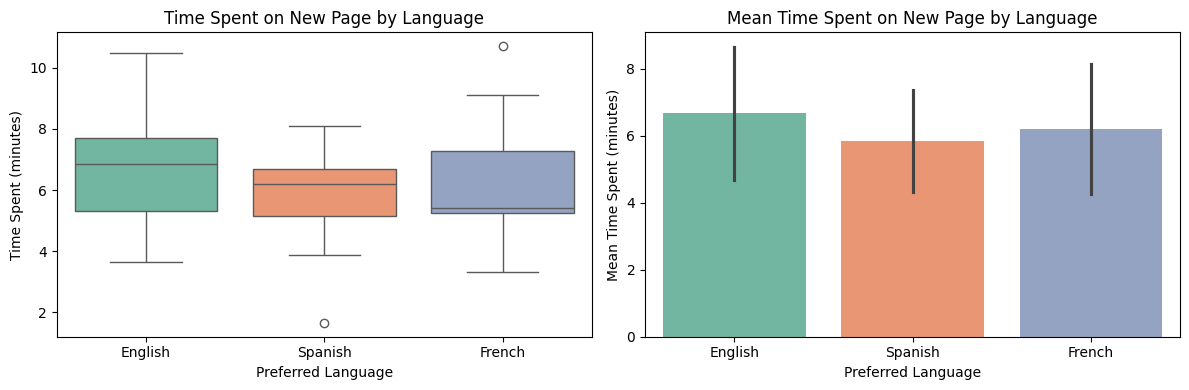

In [22]:
# Ensure data is available
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

# Users who viewed the new landing page only
new_page = data[data["landing_page"] == "new"]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(data=new_page, x="language_preferred", hue="language_preferred", legend=False, y="time_spent_on_the_page", palette="Set2")
plt.title("Time Spent on New Page by Language")
plt.xlabel("Preferred Language")
plt.ylabel("Time Spent (minutes)")

plt.subplot(1, 2, 2)
sns.barplot(
    data=new_page,
    x="language_preferred", hue="language_preferred", legend=False,
    y="time_spent_on_the_page",
    estimator="mean",
    errorbar="sd",
    palette="Set2",
)
plt.title("Mean Time Spent on New Page by Language")
plt.xlabel("Preferred Language")
plt.ylabel("Mean Time Spent (minutes)")

plt.tight_layout()
plt.show()

## **b. Formulate null and alternative hypotheses**

Let $\mu_E$, $\mu_F$, and $\mu_S$ be the mean time spent on the new landing page by English, French, and Spanish users, respectively.

$$H_0: \mu_E = \mu_F = \mu_S$$
$$H_a: \text{At least one language group has a different mean time spent on the new page}$$

We are testing whether the **mean time spent on the new page** is the **same** across users with different preferred languages.

## **c. Select the appropriate test**

We are comparing the **means of more than two groups** (English, French, and Spanish users on the new page).

The appropriate test is a **one-way ANOVA**.

Before applying the test, we check:
1. **Normality** of time spent within each language group using the Shapiro-Wilk test
2. **Equality of variances** across groups using Levene's test

**Significance level:** $\alpha = 0.05$

## **d. Data collection and preparation**

In [23]:
import pandas as pd
from scipy.stats import shapiro, levene

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

alpha = 0.05

# Users who viewed the new landing page only
new_page = data[data["landing_page"] == "new"]

# Time spent on the new page for each language group
time_english = new_page[new_page["language_preferred"] == "English"]["time_spent_on_the_page"]
time_french  = new_page[new_page["language_preferred"] == "French"]["time_spent_on_the_page"]
time_spanish = new_page[new_page["language_preferred"] == "Spanish"]["time_spent_on_the_page"]

print("Sample size (English):", len(time_english))
print("Sample size (French):", len(time_french))
print("Sample size (Spanish):", len(time_spanish))
print("Mean time (English):", round(time_english.mean(), 2))
print("Mean time (French):", round(time_french.mean(), 2))
print("Mean time (Spanish):", round(time_spanish.mean(), 2))

# Check normality assumption
print("\nShapiro-Wilk (English): p-value =", round(shapiro(time_english).pvalue, 4))
print("Shapiro-Wilk (French):  p-value =", round(shapiro(time_french).pvalue, 4))
print("Shapiro-Wilk (Spanish): p-value =", round(shapiro(time_spanish).pvalue, 4))

# Check equality of variances
print("Levene's test: p-value =", round(levene(time_english, time_french, time_spanish).pvalue, 4))

Sample size (English): 16
Sample size (French): 17
Sample size (Spanish): 17
Mean time (English): 6.66
Mean time (French): 6.2
Mean time (Spanish): 5.84

Shapiro-Wilk (English): p-value = 0.8863
Shapiro-Wilk (French):  p-value = 0.3214
Shapiro-Wilk (Spanish): p-value = 0.0901
Levene's test: p-value = 0.4671


## **e. Calculate the p-value**

In [24]:
from scipy.stats import f_oneway

# One-way ANOVA
test_stat, p_value = f_oneway(time_english, time_french, time_spanish)

print("F-statistic:", round(test_stat, 4))
print("p-value:", round(p_value, 4))

F-statistic: 0.8544
p-value: 0.432


## **f. Write the inference based on the p-value**

In [25]:
if p_value < alpha:
    print("Since p-value (", round(p_value, 4), ") < alpha (", alpha, "), we reject the null hypothesis.")
    print("Inference: The mean time spent on the new page is not the same across the different language users.")
else:
    print("Since p-value (", round(p_value, 4), ") >= alpha (", alpha, "), we fail to reject the null hypothesis.")
    print("Inference: The mean time spent on the new page is the same across the different language users.")

Since p-value ( 0.432 ) >= alpha ( 0.05 ), we fail to reject the null hypothesis.
Inference: The mean time spent on the new page is the same across the different language users.


# **Actionable Insights & Recommendations**

Summary based on hypothesis test outputs from Sections 3-6

In [26]:
# Consolidated results from all four hypothesis tests
import pandas as pd
from scipy.stats import ttest_ind, shapiro, levene, f_oneway, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

if "data" not in globals():
    data = pd.read_csv("abtest.csv")

alpha = 0.05

# Test 1: Time spent (new vs old)
time_new = data[data["landing_page"] == "new"]["time_spent_on_the_page"]
time_old = data[data["landing_page"] == "old"]["time_spent_on_the_page"]
levene_p1 = levene(time_new, time_old).pvalue
t_stat, p_time = ttest_ind(time_new, time_old, equal_var=levene_p1 > alpha, alternative="greater")

# Test 2: Conversion rate (new vs old)
new_converted = data[(data["landing_page"] == "new") & (data["converted"] == "yes")].shape[0]
old_converted = data[(data["landing_page"] == "old") & (data["converted"] == "yes")].shape[0]
n_new = (data["landing_page"] == "new").sum()
n_old = (data["landing_page"] == "old").sum()
z_stat, p_conv = proportions_ztest([new_converted, old_converted], [n_new, n_old], alternative="larger")

# Test 3: Conversion vs language
contingency_table = pd.crosstab(data["converted"], data["language_preferred"])
chi2_stat, p_lang_conv, dof, _ = chi2_contingency(contingency_table)

# Test 4: Time on new page across languages
new_page = data[data["landing_page"] == "new"]
time_english = new_page[new_page["language_preferred"] == "English"]["time_spent_on_the_page"]
time_french = new_page[new_page["language_preferred"] == "French"]["time_spent_on_the_page"]
time_spanish = new_page[new_page["language_preferred"] == "Spanish"]["time_spent_on_the_page"]
f_stat, p_anova = f_oneway(time_english, time_french, time_spanish)

results_summary = pd.DataFrame(
    {
        "Question": [
            "More time on new page?",
            "Higher conversion on new page?",
            "Conversion depends on language?",
            "Same time on new page across languages?",
        ],
        "Test": [
            "Two-sample t-test (Welch)" if levene_p1 <= alpha else "Two-sample t-test",
            "Two-proportion z-test",
            "Chi-square test",
            "One-way ANOVA",
        ],
        "Test statistic": [
            round(t_stat, 4),
            round(z_stat, 4),
            round(chi2_stat, 4),
            round(f_stat, 4),
        ],
        "p-value": [
            round(p_time, 4),
            round(p_conv, 4),
            round(p_lang_conv, 4),
            round(p_anova, 4),
        ],
        "Decision (alpha=0.05)": [
            "Reject H0" if p_time < alpha else "Fail to reject H0",
            "Reject H0" if p_conv < alpha else "Fail to reject H0",
            "Reject H0" if p_lang_conv < alpha else "Fail to reject H0",
            "Reject H0" if p_anova < alpha else "Fail to reject H0",
        ],
    }
)

print("Hypothesis test summary:")
display(results_summary)

print("\nKey metrics from the analysis:")
print(f"- Mean time on new page: {time_new.mean():.2f} min | old page: {time_old.mean():.2f} min")
print(f"- Conversion rate (new): {new_converted}/{n_new} = {new_converted/n_new:.0%} | (old): {old_converted}/{n_old} = {old_converted/n_old:.0%}")
print(f"- Mean time on new page by language: English={time_english.mean():.2f}, French={time_french.mean():.2f}, Spanish={time_spanish.mean():.2f} min")

Hypothesis test summary:


,Question,Test,Test statistic,p-value,Decision (alpha=0.05)
0,More time on new page?,Two-sample t-test (Welch),3.7868,0.0001,Reject H0
1,Higher conversion on new page?,Two-proportion z-test,2.4077,0.0080,Reject H0
2,Conversion depends on language?,Chi-square test,3.0930,0.2130,Fail to reject H0
3,Same time on new page across languages?,One-way ANOVA,0.8544,0.4320,Fail to reject H0



Key metrics from the analysis:
- Mean time on new page: 6.22 min | old page: 4.53 min
- Conversion rate (new): 33/50 = 66% | (old): 21/50 = 42%
- Mean time on new page by language: English=6.66, French=6.20, Spanish=5.84 min


## **Summary of hypothesis test results**

Based on the consolidated output above:

| Question | Test | Statistic | p-value | Decision |
|---|---|---:|---:|---|
| Do users spend more time on the new page? | Two-sample t-test (Welch) | t = 3.7868 | 0.0001 | **Reject H₀** |
| Is the new page conversion rate greater? | Two-proportion z-test | z = 2.4077 | 0.0080 | **Reject H₀** |
| Does conversion depend on preferred language? | Chi-square test | χ² = 3.0930 | 0.2130 | **Fail to reject H₀** |
| Is mean time on the new page the same across languages? | One-way ANOVA | F = 0.8544 | 0.4320 | **Fail to reject H₀** |

**Overall:** Two of four tests are statistically significant at α = 0.05. The new landing page significantly increases both time spent and conversion rate. Language does not significantly affect conversion or time spent on the new page.

## **Key insights**

1. **Higher engagement on the new landing page:** Users spend significantly more time on the new page (mean = **6.22 min**) than on the old page (mean = **4.53 min**). The t-test returned **t = 3.7868** with **p = 0.0001**, so we reject H₀ and conclude the new page keeps users engaged longer.

2. **Improved conversion performance:** The new page converts **33 out of 50 users (66%)** compared with **21 out of 50 (42%)** on the old page. The two-proportion z-test returned **z = 2.4077** with **p = 0.0080**, confirming a statistically significant improvement in conversion.

3. **Language is not a significant driver of conversion:** The chi-square test for conversion vs. preferred language gave **χ² = 3.0930** with **p = 0.2130**. We fail to reject H₀, so conversion status appears independent of whether users prefer English, French, or Spanish.

4. **Consistent time spent across languages on the new page:** For users on the new page, mean time spent is **6.66 min (English)**, **6.20 min (French)**, and **5.84 min (Spanish)**. One-way ANOVA returned **F = 0.8544** with **p = 0.4320**, so we fail to reject H₀ — the new page delivers a similar experience across language groups in this sample.

## **Recommendations for E-news Express**

1. **Roll out the new landing page:** Both significant tests (time spent and conversion rate) support replacing the old page. The new design increases average engagement by **1.69 minutes** and conversion by **24 percentage points** (66% vs 42%).

2. **Use a single unified page across languages (for now):** Since neither the chi-square test (p = 0.2130) nor the ANOVA (p = 0.4320) found significant language differences, E-news Express can deploy one new landing page for English, French, and Spanish users rather than building separate language variants immediately.

3. **Monitor post-launch KPIs:** Track conversion rate, average time on page, and new subscriber counts weekly after full rollout to confirm the A/B test gains (66% conversion, 6.22 min avg time) hold beyond the 100-user experiment.

4. **Run follow-up A/B tests on page elements:** With the new page validated, test headlines, recommended content blocks, and call-to-action placement to push conversion above the current **66%** benchmark.

5. **Increase sample size for language-specific strategies:** If future campaigns require language-targeted pages, collect more data — this 100-user test did not detect language effects, but a larger sample may be needed for finer-grained analysis.

## **Next steps**

- Deploy the new landing page to all users based on significant gains in time spent (p = 0.0001) and conversion (p = 0.0080).
- Build a dashboard for conversion rate, time on page, and subscriber growth.
- Re-run the analysis after collecting additional data to validate results at scale.
- Plan component-level A/B tests to optimize the new page further.